In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression

from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score


In [6]:
df = pd.read_csv("Admission_Predict.csv")

In [3]:
df.head()

,Serial No.,GRE Score,TOEFL Score,University Rating,SOP,LOR,CGPA,Research,Chance of Admit
0,1,337,118,4,4.5,4.5,9.65,1,0.92
1,2,324,107,4,4.0,4.5,8.87,1,0.76
2,3,316,104,3,3.0,3.5,8.00,1,0.72
3,4,322,110,3,3.5,2.5,8.67,1,0.80
4,5,314,103,2,2.0,3.0,8.21,0,0.65


In [7]:
df.shape

(400, 9)

In [8]:
df.columns

Index(['Serial No.', 'GRE Score', 'TOEFL Score', 'University Rating', 'SOP',
       'LOR ', 'CGPA', 'Research', 'Chance of Admit '],
      dtype='object')

In [11]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 9 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Serial No.         400 non-null    int64  
 1   GRE Score          400 non-null    int64  
 2   TOEFL Score        400 non-null    int64  
 3   University Rating  400 non-null    int64  
 4   SOP                400 non-null    float64
 5   LOR                400 non-null    float64
 6   CGPA               400 non-null    float64
 7   Research           400 non-null    int64  
 8   Chance of Admit    400 non-null    float64
dtypes: float64(4), int64(5)
memory usage: 28.3 KB


In [12]:
df.describe

<bound method NDFrame.describe of      Serial No.  GRE Score  TOEFL Score  University Rating  SOP  LOR   CGPA  \
0             1        337          118                  4  4.5   4.5  9.65   
1             2        324          107                  4  4.0   4.5  8.87   
2             3        316          104                  3  3.0   3.5  8.00   
3             4        322          110                  3  3.5   2.5  8.67   
4             5        314          103                  2  2.0   3.0  8.21   
..          ...        ...          ...                ...  ...   ...   ...   
395         396        324          110                  3  3.5   3.5  9.04   
396         397        325          107                  3  3.0   3.5  9.11   
397         398        330          116                  4  5.0   4.5  9.45   
398         399        312          103                  3  3.5   4.0  8.78   
399         400        333          117                  4  5.0   4.0  9.66   

     Research  Ch

In [14]:
# Clean Columns Name Space or unwanted things
df.columns = df.columns.str.strip()

In [15]:
df.columns

Index(['Serial No.', 'GRE Score', 'TOEFL Score', 'University Rating', 'SOP',
       'LOR', 'CGPA', 'Research', 'Chance of Admit'],
      dtype='object')

In [16]:
df.isnull().sum()

Serial No.           0
GRE Score            0
TOEFL Score          0
University Rating    0
SOP                  0
LOR                  0
CGPA                 0
Research             0
Chance of Admit      0
dtype: int64

In [18]:
numeric_columns = df.select_dtypes( include = np.number).columns

In [22]:
for column in numeric_columns:
    df[column] = df[column].fillna(df[column].median())
    

In [23]:
df.isnull().sum()

Serial No.           0
GRE Score            0
TOEFL Score          0
University Rating    0
SOP                  0
LOR                  0
CGPA                 0
Research             0
Chance of Admit      0
dtype: int64

In [26]:
print(df.duplicated().sum())

0


In [27]:
df = df.drop_duplicates()

In [29]:
df.shape

(400, 9)

In [30]:
df.dtypes

Serial No.             int64
GRE Score              int64
TOEFL Score            int64
University Rating      int64
SOP                  float64
LOR                  float64
CGPA                 float64
Research               int64
Chance of Admit      float64
dtype: object

In [31]:
# Remove the Serial Number

In [32]:
if 'Serial No.' in df.columns:
    df = df.drop('Serial No.',
                 axis = 1)
print("\n Columns After Remove Serial No.")
df.columns


 Columns After Remove Serial No.


Index(['GRE Score', 'TOEFL Score', 'University Rating', 'SOP', 'LOR', 'CGPA',
       'Research', 'Chance of Admit'],
      dtype='object')

In [33]:
# Target Analysis

In [35]:
print("\n Chance of Admit Statistics ")
print(df['Chance of Admit'].describe())


 Chance of Admit Statistics 
count    400.000000
mean       0.724350
std        0.142609
min        0.340000
25%        0.640000
50%        0.730000
75%        0.830000
max        0.970000
Name: Chance of Admit, dtype: float64


In [36]:
# Correlation Heatmap

In [38]:
correlation = df.corr(numeric_only = True)
print("\n Correlation with Chnace of Admit :")
print(correlation["Chance of Admit"].sort_values(ascending = False)
     )


 Correlation with Chnace of Admit :
Chance of Admit      1.000000
CGPA                 0.873289
GRE Score            0.802610
TOEFL Score          0.791594
University Rating    0.711250
SOP                  0.675732
LOR                  0.669889
Research             0.553202
Name: Chance of Admit, dtype: float64


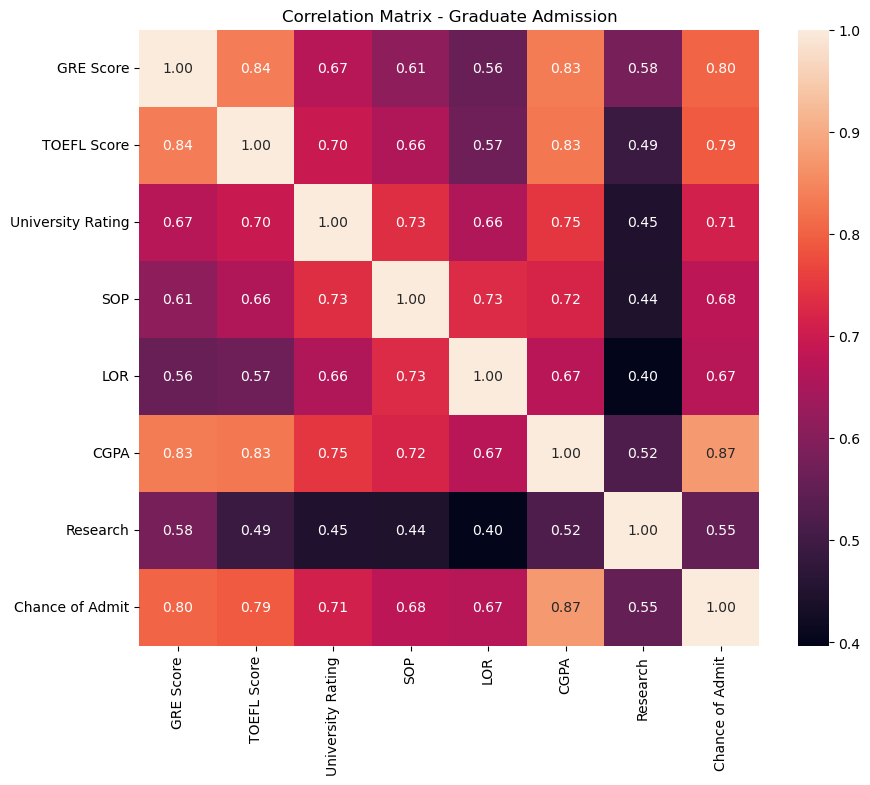

In [39]:
plt.figure(figsize = (10,8))
sns.heatmap(correlation , annot = True,fmt = ".2f")
plt.title("Correlation Matrix - Graduate Admission")
plt.title("Correlation Matrix - Graduate Admission")
plt.show()

In [41]:
X = df.drop("Chance of Admit",
            axis = 1)
y = df['Chance of Admit']

print("\n Features :")
print(X.head())

print("\n Target :")
print(y.head())

print("\n X Shape ")
print(y.shape)

print("\n y Shape ")
print(X.shape)


 Features :
   GRE Score  TOEFL Score  University Rating  SOP  LOR  CGPA  Research
0        337          118                  4  4.5  4.5  9.65         1
1        324          107                  4  4.0  4.5  8.87         1
2        316          104                  3  3.0  3.5  8.00         1
3        322          110                  3  3.5  2.5  8.67         1
4        314          103                  2  2.0  3.0  8.21         0

 Target :
0    0.92
1    0.76
2    0.72
3    0.80
4    0.65
Name: Chance of Admit, dtype: float64

 X Shape 
(400,)

 y Shape 
(400, 7)


In [42]:
# Train - Test - Split
X_train , X_test , y_train , y_test = train_test_split(
    X,
    y,
    test_size = 0.20,
    random_state = 42
)


In [43]:
print("Tranning Data :" , X_train.shape)
print("Testing data :", X_test.shape)

Tranning Data : (320, 7)
Testing data : (80, 7)


In [44]:
scaler = StandardScaler()

In [48]:
X_train_scaled = scaler.fit_transform(
    X_train)
X_test_scaled = scaler.transform(X_test)
print("Feature scaling complated !")

Feature scaling complated !


In [49]:
# Create Multiple Linear Regression Model

In [50]:
model = LinearRegression()

In [51]:
model.fit(X_train_scaled,
          y_train)
print("Multiple Linear Regression tranning Complated")

Multiple Linear Regression tranning Complated


In [52]:
print("Intercept:")
print(model.intercept_)

Intercept:
0.7252812500000001


In [53]:
coefficients = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": model.coef_
})

print("\nModel Coefficients:")

print(
    coefficients.sort_values(
        by="Coefficient",
        ascending=False
    )
)


Model Coefficients:
             Feature  Coefficient
5               CGPA     0.067381
0          GRE Score     0.020997
1        TOEFL Score     0.016395
4                LOR     0.014138
6           Research     0.011082
2  University Rating     0.008448
3                SOP    -0.000299


In [54]:
y_pred = model.predict( X_test_scaled)
print("\n First 10 Predictions :")
print(y_pred[:10])


 First 10 Predictions :
[0.65117446 0.72368741 0.93536809 0.82164316 0.58158673 0.92863016
 0.52682366 0.54308993 0.65940583 0.83834924]


In [55]:
# Model Evaluation

In [56]:
mae = mean_absolute_error(
    y_test,
    y_pred)
mse = mean_squared_error(
    y_test, y_pred)
rmse = np.sqrt(mse)

r2 = r2_score ( y_test, y_pred)

print("Multiple Linear Evaluation")
print("MAE : " ,mae)
print("MSE :",mse)
print("RMSE :", rmse)
print("R2 Score :",r2)
print("R2 Percentage :",
      r2* 100, '%')


Multiple Linear Evaluation
MAE :  0.047956733620912025
MSE : 0.004617003377285013
RMSE : 0.0679485347692282
R2 Score : 0.8212082591486991
R2 Percentage : 82.12082591486991 %


In [57]:
# Actual VS Predicted
comparison = pd.DataFrame({
    "Actual Chance": y_test.to_numpy(),
    "Predicted Chance" : y_pred})

In [58]:
print(comparison.head(20))

    Actual Chance  Predicted Chance
0            0.68          0.651174
1            0.68          0.723687
2            0.90          0.935368
3            0.79          0.821643
4            0.44          0.581587
5            0.94          0.928630
6            0.43          0.526824
7            0.36          0.543090
8            0.72          0.659406
9            0.85          0.838349
10           0.45          0.720088
11           0.93          0.907498
12           0.64          0.553545
13           0.93          0.890086
14           0.71          0.703895
15           0.53          0.686645
16           0.66          0.666573
17           0.34          0.481961
18           0.74          0.690572
19           0.96          0.974931


In [59]:
comparison = pd.DataFrame({
    "Student Index": y_test.index,
    "Actual Chance": y_test.to_numpy(),
    "Predicted Chance": y_pred
})

comparison = comparison.reset_index(
    drop=True
)

print(comparison.head(20))

    Student Index  Actual Chance  Predicted Chance
0             209           0.68          0.651174
1             280           0.68          0.723687
2              33           0.90          0.935368
3             210           0.79          0.821643
4              93           0.44          0.581587
5              84           0.94          0.928630
6             329           0.43          0.526824
7              94           0.36          0.543090
8             266           0.72          0.659406
9             126           0.85          0.838349
10              9           0.45          0.720088
11            361           0.93          0.907498
12             56           0.64          0.553545
13             72           0.93          0.890086
14            132           0.71          0.703895
15             42           0.53          0.686645
16            278           0.66          0.666573
17            376           0.34          0.481961
18            231           0.7

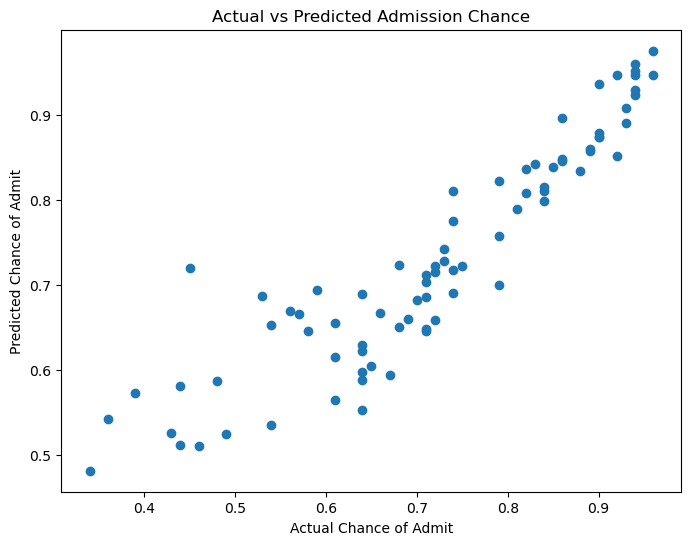

In [60]:
# ============================================================
# STEP 23: ACTUAL VS PREDICTED GRAPH
# ============================================================

plt.figure(
    figsize=(8, 6)
)

plt.scatter(
    y_test,
    y_pred
)

plt.xlabel(
    "Actual Chance of Admit"
)

plt.ylabel(
    "Predicted Chance of Admit"
)

plt.title(
    "Actual vs Predicted Admission Chance"
)

plt.show()

In [61]:
residuals = y_test - y_pred

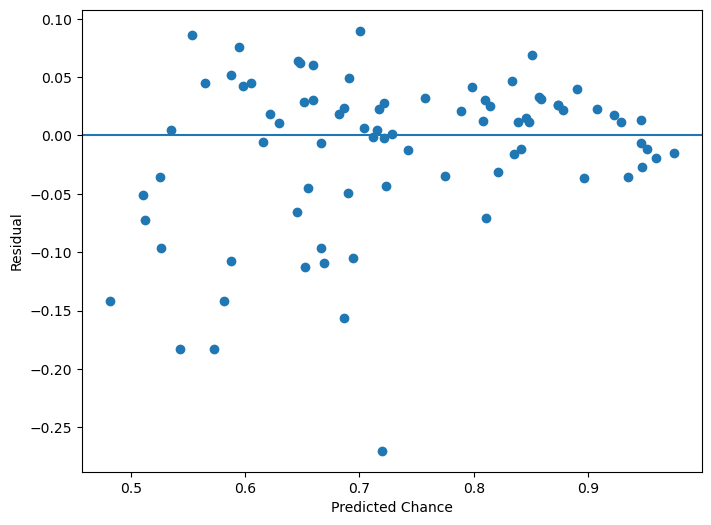

In [62]:
plt.figure(figsize = (8,6))
plt.scatter(y_pred ,residuals)
plt.axhline( y = 0)
plt.xlabel("Predicted Chance")
plt.ylabel("Residual")
plt.show()

In [64]:
# ============================================================
# STEP 25: TRAINING PERFORMANCE
# ============================================================

train_pred = model.predict(
    X_train_scaled
)

train_r2 = r2_score(
    y_train,
    train_pred
)

test_r2 = r2_score(
    y_test,
    y_pred
)


print("Training R2:", train_r2)

print("Testing R2 :", test_r2)

print(
    "Difference:",
    train_r2 - test_r2
)

Training R2: 0.7951946003191086
Testing R2 : 0.8212082591486991
Difference: -0.026013658829590502


In [65]:
# ============================================================
# STEP 26: NEW STUDENT DATA
# ============================================================

new_student = pd.DataFrame({
    "GRE Score": [330],
    "TOEFL Score": [115],
    "University Rating": [4],
    "SOP": [4],
    "LOR": [4],
    "CGPA": [9.2],
    "Research": [1]
})


print("\nNew Student:")
print(new_student)


New Student:
   GRE Score  TOEFL Score  University Rating  SOP  LOR  CGPA  Research
0        330          115                  4    4    4   9.2         1


In [66]:
# ============================================================
# STEP 27: MATCH FEATURE ORDER
# ============================================================

new_student = new_student[
    X.columns
]

print("\nFeature order:")
print(new_student.columns)


Feature order:
Index(['GRE Score', 'TOEFL Score', 'University Rating', 'SOP', 'LOR', 'CGPA',
       'Research'],
      dtype='object')


In [67]:
# ============================================================
# STEP 28: SCALE NEW STUDENT
# ============================================================

new_student_scaled = scaler.transform(
    new_student
)

In [68]:
# WRONG
scaler.fit_transform(new_student)

array([[0., 0., 0., 0., 0., 0., 0.]])

In [70]:
# ============================================================
# STEP 29: PREDICT NEW STUDENT
# ============================================================

new_prediction = model.predict(
    new_student_scaled
)


print("NEW STUDENT ADMISSION PREDICTION")

print(
    "Predicted Chance of Admit:",
    new_prediction[0]
)

NEW STUDENT ADMISSION PREDICTION
Predicted Chance of Admit: 0.866221571677804


In [71]:
# STEP 30: CONVERT TO PERCENTAGE

chance_percentage = new_prediction[0] * 100

print(
    "Admission Chance:",
    round(chance_percentage, 2),
    "%"
)

Admission Chance: 86.62 %


In [72]:
# STEP 31: SIMPLE INTERPRETATION

chance = new_prediction[0]

if chance >= 0.80:
    category = "High Chance"

elif chance >= 0.60:
    category = "Moderate Chance"

else:
    category = "Lower Chance"


print(
    "Admission Category:",
    category
)

Admission Category: High Chance
